# Smart Irrigation Advisor — Phase 1 Starter Notebook
**Course:** ML 402331 — IoT Machine Learning Project (Fall 2026/2027)  
**Student:** Mustafa Juma (ID 2410102) — individual project  
**Phase:** 1 (Idea, problem and setup)

**What this notebook does**
1. Loads a small public dataset (scikit-learn's *Diabetes* dataset) and runs a first **linear regression** (Week 3 topic).
2. Shows, on **clearly labelled synthetic data**, how my project's sensor data will be shaped and labelled. The real ESP32 data arrives in Phase 2.

> **AI-use statement:** an AI assistant (Claude) helped draft this notebook. I have run it and am responsible for understanding every line.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42          # fixed seed so every run gives the same numbers
np.random.seed(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (6, 4)
print("Setup complete")

Setup complete


## 2. Load a small public dataset
We use the **Diabetes** dataset that ships with scikit-learn (Efron et al., 2004): 442 samples, 10 numeric features, and a numeric target (disease progression after one year). It is only a **practice dataset** for the regression pipeline; it is not my project data.

In [2]:
data = load_diabetes(as_frame=True)
df = data.frame                      # 10 feature columns + 'target'
print("Shape (rows, columns):", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
df.head()

Shape (rows, columns): (442, 11)
Missing values: 0


        age       sex       bmi        bp        s1        s2        s3        s4        s5        s6  target
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401 -0.002592  0.019907 -0.017646   151.0
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412 -0.039493 -0.068332 -0.092204    75.0
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356 -0.002592  0.002861 -0.025930   141.0
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038  0.034309  0.022688 -0.009362   206.0
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142 -0.002592 -0.031988 -0.046641   135.0

In [3]:
df.describe().T[["mean", "std", "min", "max"]].round(3)

           mean     std     min      max
age      -0.000   0.048  -0.107    0.111
sex       0.000   0.048  -0.045    0.051
bmi      -0.000   0.048  -0.090    0.171
bp       -0.000   0.048  -0.112    0.132
s1       -0.000   0.048  -0.127    0.154
s2        0.000   0.048  -0.116    0.199
s3       -0.000   0.048  -0.102    0.181
s4       -0.000   0.048  -0.076    0.185
s5        0.000   0.048  -0.126    0.134
s6        0.000   0.048  -0.138    0.136
target  152.133  77.093  25.000  346.000

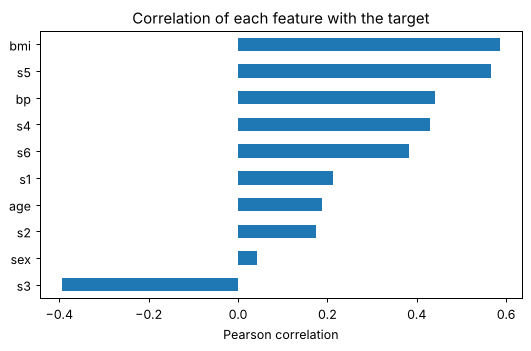

In [4]:
# Which features move together with the target?
corr = df.corr()["target"].drop("target").sort_values()
corr.plot(kind="barh", title="Correlation of each feature with the target")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

## 3. Train/test split
80 % of the rows train the model, 20 % are held back to measure how well it generalises.

In [5]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Train rows: 353 | Test rows: 89


## 4. First linear regression
### 4a. Simple linear regression (one feature: `bmi`)

Intercept: 152.00 | Slope: 998.58
Test RMSE: 63.73 | Test R2: 0.233


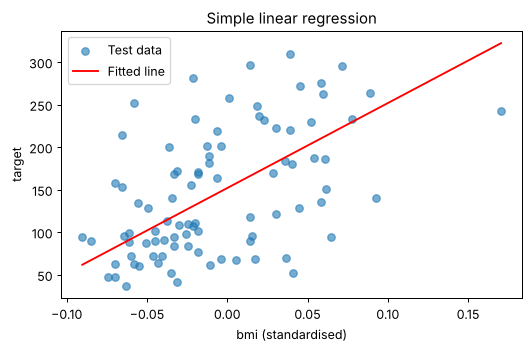

In [6]:
simple = LinearRegression().fit(X_train[["bmi"]], y_train)
pred_simple = simple.predict(X_test[["bmi"]])

rmse_simple = float(np.sqrt(mean_squared_error(y_test, pred_simple)))
r2_simple = float(r2_score(y_test, pred_simple))
print(f"Intercept: {simple.intercept_:.2f} | Slope: {simple.coef_[0]:.2f}")
print(f"Test RMSE: {rmse_simple:.2f} | Test R2: {r2_simple:.3f}")

# Plot the fitted line over the test points
order = np.argsort(X_test["bmi"].values)
plt.scatter(X_test["bmi"], y_test, alpha=0.6, label="Test data")
plt.plot(X_test["bmi"].values[order], pred_simple[order], color="red", label="Fitted line")
plt.xlabel("bmi (standardised)")
plt.ylabel("target")
plt.title("Simple linear regression")
plt.legend()
plt.tight_layout()
plt.show()

### 4b. Multiple linear regression (all 10 features)

In [7]:
model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

mse = float(mean_squared_error(y_test, pred))
rmse = float(np.sqrt(mse))
r2 = float(r2_score(y_test, pred))
print(f"Test MSE: {mse:.2f} | Test RMSE: {rmse:.2f} | Test R2: {r2:.3f}")

# Coefficients show how much each feature pushes the prediction
coefs = pd.Series(model.coef_, index=X.columns).sort_values()
coefs.round(1)

Test MSE: 2900.19 | Test RMSE: 53.85 | Test R2: 0.453


s1    -931.5
sex   -242.0
age     37.9
s6      48.7
s3     163.4
s4     275.3
bp     347.7
s2     518.1
bmi    542.4
s5     736.2

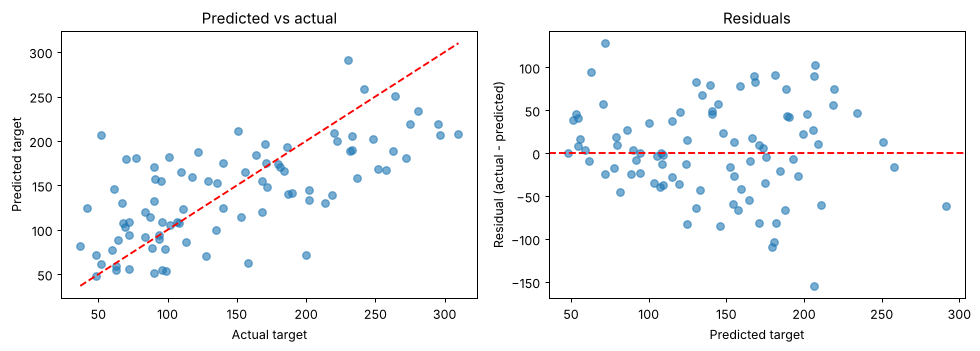

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Left: predicted vs actual (points on the diagonal = perfect predictions)
axes[0].scatter(y_test, pred, alpha=0.6)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[0].plot(lims, lims, "r--")
axes[0].set_xlabel("Actual target")
axes[0].set_ylabel("Predicted target")
axes[0].set_title("Predicted vs actual")

# Right: residuals should scatter around zero with no obvious pattern
axes[1].scatter(pred, y_test - pred, alpha=0.6)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted target")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residuals")

plt.tight_layout()
plt.show()

### 4c. Check stability with 5-fold cross-validation

In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_r2 = cross_val_score(LinearRegression(), X, y, cv=cv, scoring="r2")
print("R2 per fold:", np.round(cv_r2, 3))
print(f"Mean R2: {cv_r2.mean():.3f} (+/- {cv_r2.std():.3f})")

summary = pd.DataFrame(
    {"model": ["Simple (bmi only)", "Multiple (10 features)"],
     "test_RMSE": [round(rmse_simple, 2), round(rmse, 2)],
     "test_R2": [round(r2_simple, 3), round(r2, 3)]}
)
summary

R2 per fold: [0.453 0.573 0.391 0.584 0.391]
Mean R2: 0.478 (+/- 0.085)


                    model  test_RMSE  test_R2
0       Simple (bmi only)      63.73    0.233
1  Multiple (10 features)      53.85    0.453

**Reading the result.** Using all 10 features explains more of the target than `bmi` alone, but a large share of the variation remains unexplained. That is a useful reminder for my project: the model is only as good as the features I log, so I will choose sensors and engineered features carefully.

## 5. Preview of my project data (synthetic, for pipeline practice only)
> **This section uses simulated numbers, not real measurements, so its scores say nothing about real-world performance.** It only shows the *shape* of the data my ESP32 will log in Phase 2 and how I plan to build the label. All of it will be replaced by real sensor logs.

Planned columns: `timestamp`, `soil_moisture_pct`, `air_temp_c`, `humidity_pct`.  
Planned label: **`needs_water_60min` = 1** if soil moisture drops to the critical level `T` (or below) at any point in the **next 60 minutes**, otherwise 0.

In [10]:
rng = np.random.default_rng(RANDOM_STATE)

n = 1500                                              # one reading every 5 minutes (about 5 days)
t = pd.date_range("2026-01-01", periods=n, freq="5min")
hour = t.hour + t.minute / 60

# Simulated day/night pattern for air temperature and humidity
temp = 24 + 6 * np.sin(2 * np.pi * (hour - 9) / 24) + rng.normal(0, 0.5, n)
hum = 55 - 15 * np.sin(2 * np.pi * (hour - 9) / 24) + rng.normal(0, 2, n)

# Simulated soil drying: hotter and drier air dries the soil faster
moist = np.empty(n)
moist[0] = 70.0
watered = np.zeros(n, dtype=bool)                     # marks simulated watering events
for i in range(1, n):
    loss = 0.08 + 0.004 * (temp[i] - 20) + 0.001 * (60 - hum[i])
    moist[i] = moist[i - 1] - loss + rng.normal(0, 0.15)
    if moist[i] < 25:                                 # the "plant" gets watered
        moist[i] = 70 + rng.normal(0, 1)
        watered[i] = True

obs = moist + rng.normal(0, 0.8, n)                  # sensor reading = true moisture + measurement noise

raw = pd.DataFrame({"timestamp": t, "soil_moisture_pct": obs,
                    "air_temp_c": temp, "humidity_pct": hum})
print("Simulated rows:", len(raw), "| Simulated watering events:", int(watered.sum()))
raw.head()

Simulated rows: 1500 | Simulated watering events: 3


            timestamp  soil_moisture_pct  air_temp_c  humidity_pct
0 2026-01-01 00:00:00          68.953866   19.909718     64.474012
1 2026-01-01 00:05:00          70.752911   19.145824     64.586253
2 2026-01-01 00:10:00          69.586581   19.951562     68.709454
3 2026-01-01 00:15:00          71.650691   19.959244     66.938177
4 2026-01-01 00:20:00          70.669254   18.428216     66.067199

In [11]:
HORIZON = 12              # 12 readings x 5 min = 60 minutes ahead
T_CRIT = 30.0             # critical moisture level (%); will be calibrated per plant in Phase 2

moist_s = pd.Series(obs)                                          # labels come from the logged (noisy) readings
future_min = moist_s.rolling(HORIZON).min().shift(-HORIZON)      # lowest value in the next 60 min
future_val = moist_s.shift(-HORIZON)                              # value exactly 60 min ahead
future_watered = pd.Series(watered).astype(int).rolling(HORIZON).sum().shift(-HORIZON)

data_syn = raw.copy()
data_syn["hour"] = hour
data_syn["moisture_in_60min"] = future_val                        # regression target (this notebook)
data_syn["needs_water_60min"] = (future_min <= T_CRIT).astype(int)  # classification label (Phase 2)

# Keep only rows whose next 60 minutes contain no simulated watering event
data_syn = data_syn[future_watered == 0].dropna()
print("Usable rows:", len(data_syn))
print("Label balance (0 = fine, 1 = needs water):")
print(data_syn["needs_water_60min"].value_counts().sort_index().to_string())

Usable rows: 1452
Label balance (0 = fine, 1 = needs water):
needs_water_60min
0    1313
1     139


Synthetic test RMSE: 1.33 moisture points | R2: 0.991


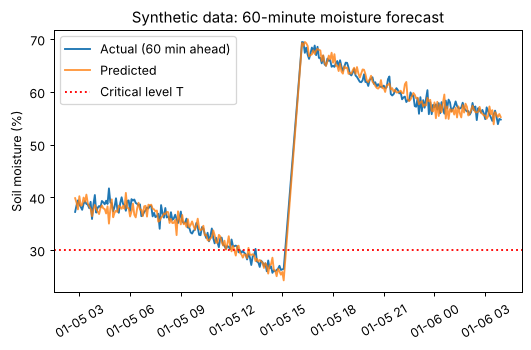

In [12]:
# First linear regression on the project-style data: forecast soil moisture 60 minutes ahead.
features = ["soil_moisture_pct", "air_temp_c", "humidity_pct", "hour"]

# Time-ordered split (no shuffling): train on the past, test on the future.
split = int(len(data_syn) * 0.8)
train_syn, test_syn = data_syn.iloc[:split], data_syn.iloc[split:]

lin = LinearRegression().fit(train_syn[features], train_syn["moisture_in_60min"])
pred_syn = lin.predict(test_syn[features])

rmse_syn = float(np.sqrt(mean_squared_error(test_syn["moisture_in_60min"], pred_syn)))
r2_syn = float(r2_score(test_syn["moisture_in_60min"], pred_syn))
print(f"Synthetic test RMSE: {rmse_syn:.2f} moisture points | R2: {r2_syn:.3f}")

plt.plot(test_syn["timestamp"], test_syn["moisture_in_60min"], label="Actual (60 min ahead)")
plt.plot(test_syn["timestamp"], pred_syn, label="Predicted", alpha=0.8)
plt.axhline(T_CRIT, color="red", linestyle=":", label="Critical level T")
plt.ylabel("Soil moisture (%)")
plt.title("Synthetic data: 60-minute moisture forecast")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 6. What comes next (Phase 2)
- Build the ESP32 circuit (capacitive soil-moisture sensor + DHT22) and log readings to CSV.
- Collect at least 500 labelled rows (target: more than 2,000) covering several dry-down and re-watering cycles.
- Clean and plot the data, then train a baseline logistic regression (with Ridge/Lasso-style regularisation) and evaluate it with 5-fold cross-validation.

## References
- B. Efron, T. Hastie, I. Johnstone and R. Tibshirani, "Least angle regression," *Annals of Statistics*, vol. 32, no. 2, pp. 407–499, 2004.
- F. Pedregosa et al., "Scikit-learn: Machine learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.